In [1]:
import kagglehub
kagglehub.login()

In [2]:
import kagglehub
# Download latest version
path = kagglehub.competition_download('dog-breed-identification')

print("Path to competition files:", path)

100%|██████████| 691M/691M [03:17<00:00, 3.67MB/s] 

Extracting files...


Path to competition files: /home/ubuntu24/.cache/kagglehub/competitions/dog-breed-identification


In [1]:
import cv2 
import numpy as np 
import pandas as pd 
from tensorflow.keras.preprocessing.image import ImageDataGenerator 
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.applications.resnet_v2 import ResNet50V2, preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


I0000 00:00:1791488998.354453   22502 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import tensorflow as tf
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
df_labels = pd.read_csv("dog-breed-identification/labels.csv")
train_file = 'dog-breed-identification/train/'
test_file  = 'dog-breed-identification/test/'

In [4]:
print("Total number of unique Dog Breeds: ", len(df_labels.breed.unique()))

Total number of unique Dog Breeds:  120


In [5]:
num_breeds = 60
im_size = 224
batch_size = 32
encoder = LabelEncoder()

In [6]:
breed_dict = list(df_labels['breed'].value_counts().keys())
new_list = sorted(breed_dict, reverse=True)[:num_breeds*2+1:2]
df_labels = df_labels.query('breed in @new_list')

In [7]:
df_labels['img_file'] = df_labels['id'].apply(lambda x: x+ ".jpg")

In [8]:
train_x = np.zeros((len(df_labels), im_size, im_size, 3), dtype='float32')
for i, img_id in enumerate(df_labels['img_file']):
    img = cv2.resize(cv2.imread(train_file+img_id, cv2.IMREAD_COLOR), ((im_size, im_size)))
    img_array = preprocess_input(np.expand_dims(np.array(img[...,::-1].astype(np.float32)).copy(), axis=0))
    train_x[i] = img_array

In [9]:
train_y = encoder.fit_transform(df_labels["breed"].values)

In [10]:
x_train, x_test, y_train, y_test = train_test_split(train_x, train_y, test_size=0.2, random_state=42)

In [11]:
train_datagen = ImageDataGenerator(rotation_range=45, width_shift_range=0.2, height_shift_range=0.2, shear_range=0.2, zoom_range=0.25, horizontal_flip=True, fill_mode='nearest')
train_generator = train_datagen.flow(x_train, y_train, batch_size=batch_size)
test_datagen = ImageDataGenerator()
test_generator = test_datagen.flow(x_test,y_test, batch_size=batch_size)

In [12]:
resnet = ResNet50V2(input_shape=[im_size, im_size, 3], weights='imagenet', include_top=False)
for layer in resnet.layers:
    layer.trainable = False
x = resnet.output
x = BatchNormalization()(x)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x= Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)

I0000 00:00:1791489161.160029   22502 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2145 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [13]:
predictions = Dense(num_breeds, activation='softmax', dtype='float32')(x)
model = Model(inputs=resnet.input, outputs=predictions)

In [14]:
epochs = 20
learning_rate = 1e-3
optimizer = RMSprop(learning_rate=learning_rate, rho=0.9)
model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=["accuracy"])
hist = model.fit(train_generator, epochs=epochs, validation_data=test_generator)
model.save("model.keras")

Epoch 1/20


I0000 00:00:1791489233.490690   22502 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
W0000 00:00:1791489240.955156   22690 cpu_allocator_impl.cc:82] Allocation of 19267584 exceeds 10% of free system memory.
I0000 00:00:1791489240.991758   22637 service.cc:153] XLA service 0x7cb9ec034390 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791489240.992177   22637 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791489241.319625   22637 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
W0000 00:00:1791489241.410233   22690 cpu_allocator_impl.cc:82] Allocation of 19267584 exceeds 10% of free system memory.
I0000 00:00:1791489243.190039   22637 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1791489243.362217   22637 dot_me

  1/130 ━━━━━━━━━━━━━━━━━━━━ 58:21 27s/step - accuracy: 0.0312 - loss: 4.4655

I0000 00:00:1791489260.462434   22637 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


  3/130 ━━━━━━━━━━━━━━━━━━━━ 31s 250ms/step - accuracy: 0.0521 - loss: 4.2724

...

  5/130 ━━━━━━━━━━━━━━━━━━━━ 41s 331ms/step - accuracy: 0.0750 - loss: 4.1449

W0000 00:00:1791489261.799412   22690 cpu_allocator_impl.cc:82] Allocation of 19267584 exceeds 10% of free system memory.


 60/130 ━━━━━━━━━━━━━━━━━━━━ 24s 347ms/step - accuracy: 0.3516 - loss: 2.6601

I0000 00:00:1791489283.382867   22637 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_10080__.173


130/130 ━━━━━━━━━━━━━━━━━━━━ 110s 646ms/step - accuracy: 0.4505 - loss: 2.1112 - val_accuracy: 0.7517 - val_loss: 0.7885
Epoch 2/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 41s 312ms/step - accuracy: 0.6205 - loss: 1.2913 - val_accuracy: 0.7836 - val_loss: 0.7205
Epoch 3/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 41s 312ms/step - accuracy: 0.6727 - loss: 1.1213 - val_accuracy: 0.7816 - val_loss: 0.7230
Epoch 4/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 41s 316ms/step - accuracy: 0.6865 - loss: 1.0904 - val_accuracy: 0.7729 - val_loss: 0.7059
Epoch 5/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 35s 266ms/step - accuracy: 0.7036 - loss: 1.0454 - val_accuracy: 0.7816 - val_loss: 0.7404
Epoch 6/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 35s 267ms/step - accuracy: 0.7203 - loss: 0.9739 - val_accuracy: 0.7836 - val_loss: 0.7282
Epoch 7/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 38s 292ms/step - accuracy: 0.7324 - loss: 0.9535 - val_accuracy: 0.7720 - val_loss: 0.7698
Epoch 8/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 35s 271ms/step - accuracy: 0.7374 - loss: 0.9235 - va

1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step


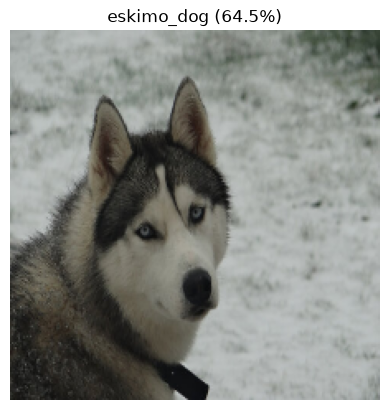

Predicted Breed for this Dog is: eskimo_dog


In [17]:
import matplotlib.pyplot as plt

model = load_model("model.keras")

pred_img_path = 'test.jpg'
img_bgr = cv2.resize(cv2.imread(pred_img_path, cv2.IMREAD_COLOR), (im_size, im_size))
pred_img_array = preprocess_input(np.expand_dims(img_bgr[..., ::-1].astype(np.float32), axis=0))
pred_val = model.predict(pred_img_array)

pred_breed = encoder.classes_[np.argmax(pred_val)]
confidence = np.max(pred_val) * 100

plt.imshow(img_bgr[..., ::-1])  
plt.title(f"{pred_breed} ({confidence:.1f}%)")
plt.axis('off')
plt.show()
print("Predicted Breed for this Dog is:", pred_breed)